# Video resolution vs. pose-tracking accuracy in bouldering

**Question:** How much does MediaPipe pose-tracking accuracy drop as video resolution falls? Is the drop larger for distal joints (wrists, ankles) than for proximal joints (shoulders, hips)?

- **Reference:** MediaPipe PoseLandmarker (full) on each clip at its native resolution (1080p or 4K).
- **Test levels:** the same frames downscaled so the long side is 1280, 854, 640, 426, 320 px (720p … ~180p).
- **Error:** distance between test and reference landmark, divided by torso length (scale-free).
- **Accuracy:** PCK@0.1 = share of joints within 0.1 torso lengths of the reference.

This notebook merges `resolution_study.py` (pose estimation) and `resolution_stats.py` (statistics + figure).

**Data:** the six graded clips (`2Q_…` to `5Q_…`) are in `data/`. Files that don't start with a grade (e.g. `5.10d_Red_E_2026A.MOV`, `Video Project 3.mp4`) are ignored.

```bash
pip install mediapipe opencv-python numpy pandas scipy statsmodels matplotlib
```

## 1. Setup and configuration
These replace the command-line arguments of the original scripts.

In [1]:
import os, re
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, cv2
from scipy import stats
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
%matplotlib inline

CLIPS_DIR  = "data"                       # clips named like 4Q_Square_D_2026A.MOV
MODEL      = "pose_landmarker_full.task"
MAX_FRAMES = 300                           # 300 reproduces the report
OUT_DIR    = "results"
N_WORKERS  = os.cpu_count()                # set to 1 to run strictly sequentially
os.makedirs(OUT_DIR, exist_ok=True)

LEVELS = [None, 1280, 854, 640, 426, 320]  # None = native
GROUPS = {"distal (wrists, ankles)": [15, 16, 27, 28],
          "proximal (shoulders, hips)": [11, 12, 23, 24],
          "middle (elbows, knees)": [13, 14, 25, 26]}

## 2. Pose estimation at one resolution level

In [2]:
def run(args):
    clip, model, level, max_frames = args
    import mediapipe as mp
    from mediapipe.tasks import python as mpp
    from mediapipe.tasks.python import vision
    cap = cv2.VideoCapture(clip); fps = cap.get(cv2.CAP_PROP_FPS) or 30
    opts = vision.PoseLandmarkerOptions(base_options=mpp.BaseOptions(model_asset_path=model),
                                        running_mode=vision.RunningMode.VIDEO)
    out = np.full((max_frames, 33, 3), np.nan)
    with vision.PoseLandmarker.create_from_options(opts) as lmk:
        for i in range(max_frames):
            ok, f = cap.read()
            if not ok:
                break
            h, w = f.shape[:2]
            if level is not None and max(h, w) > level:
                s = level / max(h, w); f = cv2.resize(f, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)
            r = lmk.detect_for_video(mp.Image(image_format=mp.ImageFormat.SRGB,
                                              data=cv2.cvtColor(f, cv2.COLOR_BGR2RGB)), int(i * 1000 / fps))
            if r.pose_landmarks:
                out[i] = [(p.x, p.y, p.visibility) for p in r.pose_landmarks[0]]
    cap.release()
    return clip, level, out

## 3. Run every clip × resolution level
36 runs (6 clips × 6 levels); about 10 minutes on a 2-core CPU.

*The original script used `ProcessPoolExecutor`, which can't pickle functions defined inside a notebook on Windows, so this uses threads instead.*

In [3]:
clips = [os.path.join(CLIPS_DIR, c) for c in sorted(os.listdir(CLIPS_DIR)) if re.match(r"\dQ_", c)]
jobs = [(c, MODEL, l, MAX_FRAMES) for c in clips for l in LEVELS]
res = {}
with ThreadPoolExecutor(max_workers=N_WORKERS) as ex:
    for clip, level, arr in ex.map(run, jobs):
        res[(clip, level)] = arr; print("done", os.path.basename(clip), level, flush=True)

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1792508580.802028     299 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792508580.806471     300 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792508580.848109     298 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792508580.855821     301 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


W0000 00:00:1792508581.136537     300 landmark_projection_calculator.cc:78] Using NORM_RECT without IMAGE_DIMENSIONS is only supported for the square ROI. Provide IMAGE_DIMENSIONS or use PROJECTION_MATRIX.


W0000 00:00:1792508607.309466     324 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792508607.366102     325 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


done 2Q_Rectangle_C_2026A.mp4 None


done 2Q_Rectangle_C_2026A.mp4 1280


...

W0000 00:00:1792508843.885091     680 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792508843.917416     680 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


done 5Q_Rectangle_A_2026A.MOV 640


W0000 00:00:1792508845.638149     688 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792508845.653522     687 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


done 5Q_Rectangle_A_2026A.MOV 426


done 5Q_Rectangle_A_2026A.MOV 320


## 4. Error and PCK@0.1 against the native-resolution reference

In [4]:
rows = []
for c in clips:
    ref = res[(c, None)]
    cap = cv2.VideoCapture(c); native = int(max(cap.get(3), cap.get(4))); cap.release()
    torso = np.nanmedian(np.linalg.norm(ref[:, [11, 12], :2].mean(1) - ref[:, [23, 24], :2].mean(1), axis=1))
    for l in LEVELS[1:]:
        if l >= native:
            continue
        t = res[(c, l)]
        for g, idx in GROUPS.items():
            err = np.linalg.norm(t[:, idx, :2] - ref[:, idx, :2], axis=2) / torso  # (frames, joints)
            valid = ~np.isnan(ref[:, idx, 0])
            detected = ~np.isnan(t[:, idx, 0]) & valid
            e = err[detected]
            rows.append(dict(clip=os.path.basename(c), native_px=native, level_px=l, group=g,
                             median_err=np.median(e), pck10=np.mean(e < 0.1) * detected.sum() / max(valid.sum(), 1),
                             detect_rate=detected.sum() / max(valid.sum(), 1),
                             mean_visibility=np.nanmean(t[:, idx, 2])))
df = pd.DataFrame(rows); df.to_csv(os.path.join(OUT_DIR, "resolution_results.csv"), index=False)
df.round(3)

,clip,native_px,level_px,group,median_err,pck10,detect_rate,mean_visibility
0,2Q_Rectangle_C_2026A.mp4,3840,1280,"distal (wrists, ankles)",0.045,0.708,0.969,0.634
1,2Q_Rectangle_C_2026A.mp4,3840,1280,"proximal (shoulders, hips)",0.026,0.881,0.969,0.999
2,2Q_Rectangle_C_2026A.mp4,3840,1280,"middle (elbows, knees)",0.039,0.769,0.969,0.647
3,2Q_Rectangle_C_2026A.mp4,3840,854,"distal (wrists, ankles)",0.048,0.702,0.958,0.645
4,2Q_Rectangle_C_2026A.mp4,3840,854,"proximal (shoulders, hips)",0.027,0.875,0.958,0.999
...,...,...,...,...,...,...,...,...
85,5Q_Rectangle_A_2026A.MOV,1920,426,"proximal (shoulders, hips)",0.019,0.994,1.000,0.999
86,5Q_Rectangle_A_2026A.MOV,1920,426,"middle (elbows, knees)",0.032,0.889,1.000,0.638
87,5Q_Rectangle_A_2026A.MOV,1920,320,"distal (wrists, ankles)",0.050,0.742,1.000,0.692
88,5Q_Rectangle_A_2026A.MOV,1920,320,"proximal (shoulders, hips)",0.026,0.992,1.000,0.999


## 5. Statistics: Friedman and Page trend tests, mixed model
Start here to skip the pose estimation and reuse an existing `resolution_results.csv`.

In [5]:
df = pd.read_csv(os.path.join(OUT_DIR, "resolution_results.csv"))
lines = []
for g, sub in df.groupby("group"):
    w = sub.pivot(index="clip", columns="level_px", values="pck10").sort_index(axis=1, ascending=False)
    w = w.dropna()
    fr = stats.friedmanchisquare(*[w[c] for c in w.columns])
    # Page's trend test: ordered alternative, accuracy decreases monotonically with resolution
    pg = stats.page_trend_test(w.values, ranked=False)  # columns already ordered high -> low res
    pg_dec = stats.page_trend_test(w.values[:, ::-1])   # predicts increasing rank from low->high res
    lines.append(f"{g}: Friedman chi2={fr.statistic:.2f}, p={fr.pvalue:.4f}; "
                 f"Page L={pg_dec.statistic:.1f}, p={pg_dec.pvalue:.4f}; mean PCK by level: "
                 + ", ".join(f"{c}px={w[c].mean():.3f}" for c in w.columns))
df["log2_px"] = np.log2(df["level_px"])
df["log_err"] = np.log10(df["median_err"] + 1e-4)
df["grp"] = df["group"].str.split().str[0]
m = smf.mixedlm("log_err ~ log2_px * C(grp, Treatment('proximal'))", df, groups=df["clip"]).fit(reml=True)
txt = "\n".join(lines) + "\n\n" + str(m.summary())
open(os.path.join(OUT_DIR, "stats.txt"), "w").write(txt); print(txt)

distal (wrists, ankles): Friedman chi2=23.83, p=0.0001; Page L=329.5, p=0.0000; mean PCK by level: 1280px=0.868, 854px=0.849, 640px=0.836, 426px=0.693, 320px=0.651
middle (elbows, knees): Friedman chi2=22.93, p=0.0001; Page L=328.0, p=0.0000; mean PCK by level: 1280px=0.909, 854px=0.890, 640px=0.877, 426px=0.749, 320px=0.707
proximal (shoulders, hips): Friedman chi2=18.61, p=0.0009; Page L=321.0, p=0.0000; mean PCK by level: 1280px=0.963, 854px=0.956, 640px=0.948, 426px=0.838, 320px=0.825

                           Mixed Linear Model Regression Results
Model:                          MixedLM             Dependent Variable:             log_err
No. Observations:               90                  Method:                         REML   
No. Groups:                     6                   Scale:                          0.0049 
Min. group size:                15                  Log-Likelihood:                 83.7720
Max. group size:                15                  Converged:          

## 6. Figure

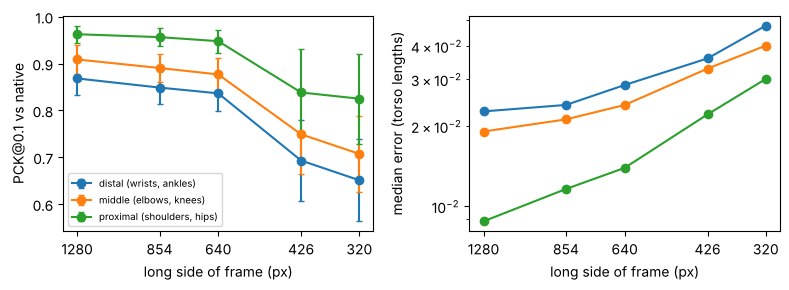

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(8, 3))
for g, sub in df.groupby("group"):
    s = sub.groupby("level_px").agg(pck=("pck10", "mean"), se=("pck10", "sem"), err=("median_err", "median"))
    ax[0].errorbar(s.index, s["pck"], yerr=s["se"], marker="o", capsize=2, label=g)
    ax[1].plot(s.index, s["err"], marker="o", label=g)
for a_ in ax:
    a_.set_xscale("log", base=2); a_.set_xticks([320, 426, 640, 854, 1280], ["320", "426", "640", "854", "1280"])
    a_.set_xlabel("long side of frame (px)"); a_.invert_xaxis()
ax[0].set_ylabel("PCK@0.1 vs native"); ax[1].set_ylabel("median error (torso lengths)"); ax[1].set_yscale("log")
ax[0].legend(fontsize=7); fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "resolution.png"), dpi=200)
plt.show()